# Modelagem preditiva — Hipotireoidismo

**Base:** Hypothyroid  
**Variável-alvo:** `binaryClass`  
**Codificação:** `P = 0` e `N = 1`  
**Preparação e divisão:** notebook  **[01_EDA](01_EDA.ipynb)**.

**OBJETIVO**

Desenvolver, treinar e comparar modelos de classificação para `binaryClass`, investigando desempenho, estabilidade e contribuição das variáveis.
___
<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">

> **Nota metodológica**
>
> A divisão treino/validação já foi realizada no notebook **[01_EDA](01_EDA.ipynb)**. `df_treino.csv` será utilizado em todo o desenvolvimento, incluindo pré-processamento, validação cruzada e seleção dos modelos. `df_validacao.csv` permanecerá reservado e será carregado somente na avaliação final.
> A validação cruzada ocorrerá dentro do treinamento. Imputação, padronização e codificação serão ajustadas dentro dos pipelines em cada fold. Os resultados representam a capacidade de reproduzir os rótulos existentes em `binaryClass`; não equivalem automaticamente à validação de um diagnóstico clínico.
</div>

### Principais achados

<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">

> **1. O TSH apresentou predominância na capacidade preditiva dos modelos.**\
> A análise de importância por permutação destacou essa variável nos três algoritmos. Sua remoção provocou queda expressiva no F1: XGBoost (0,966 → 0,439), Random Forest (0,957 → 0,493) e Regressão Logística (0,817 → 0,372).

> **2. TT4, FTI e T3 ganharam relevância na ausência do TSH.**\
> Na análise de sensibilidade, essas variáveis concentraram as maiores importâncias, indicando que os hormônios tireoidianos avaliados também contribuíram para a classificação, embora com menor capacidade preditiva no conjunto analisado.

> **3. Random Forest e XGBoost apresentaram desempenho praticamente equivalente.**\
> Ambos alcançaram PR-AUC e ROC-AUC de 1,000. O Random Forest obteve F1 de 0,992 e o XGBoost, 0,991. Cada modelo apresentou apenas um erro de classificação, em classes diferentes.
</div>

___


**ESTRATÉGIA EXPERIMENTAL**

1. Carregar e auditar a base de treinamento.
2. Identificar os tipos de preditores e configurar o pré-processamento.
3. Comparar modelos baseline por validação cruzada.
4. Investigar estabilidade e importância das variáveis.
5. Realizar análise de sensibilidade sem `TSH`.
6. Investigar associações entre variáveis categóricas e a classe.
7. Avaliar os modelos no conjunto de validação reservado.

## 1. Configuração do ambiente e carregamento

In [1]:
from setup_notebook import *

DATA_DIR = PROJECT_ROOT / "data"
PATH_TREINO = DATA_DIR / "df_treino.csv"
PATH_VALIDACAO = DATA_DIR / "df_validacao.csv"


COR=color_palette21
COR_R=COR[::-1]

COR2=color_palette41
COR2_R=COR2[::-1]

sns.set_palette(COR)
sns.set_style("whitegrid")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

print(f"Projeto        : {PROJECT_ROOT}")
print(f"Notebook       : {NOTEBOOK_DIR}")
print("Bibliotecas e funções auxiliares carregadas.")
sns.color_palette(COR)

Projeto        : /home/akel/PycharmProjects/EBAC/Diagnostico_hipotireoidismo
Notebook       : /home/akel/PycharmProjects/EBAC/Diagnostico_hipotireoidismo/notebook
Bibliotecas e funções auxiliares carregadas.


[(0.0, 0.2980392156862745, 0.2980392156862745),
 (0.0, 0.4, 0.4),
 (0.0, 0.5019607843137255, 0.5019607843137255),
 (0.09803921568627451, 0.5686274509803921, 0.5686274509803921),
 (0.1607843137254902, 0.6392156862745098, 0.6392156862745098),
 (0.25098039215686274, 0.7098039215686275, 0.7098039215686275),
 (0.3333333333333333, 0.7803921568627451, 0.7803921568627451),
 (0.4, 0.8509803921568627, 0.8509803921568627),
 (0.5019607843137255, 0.9254901960784314, 0.9254901960784314),
 (0.6, 1.0, 1.0),
 (1.0, 0.8352941176470589, 0.5019607843137255),
 (1.0, 0.7686274509803922, 0.3764705882352941),
 (1.0, 0.6980392156862745, 0.25098039215686274),
 (1.0, 0.6274509803921569, 0.12549019607843137),
 (1.0, 0.5568627450980392, 0.0),
 (1.0, 0.48627450980392156, 0.0),
 (1.0, 0.39215686274509803, 0.0),
 (1.0, 0.2980392156862745, 0.0),
 (1.0, 0.2, 0.0),
 (1.0, 0.10196078431372549, 0.0),
 (1.0, 0.0, 0.0)]

## 2. Carregamento e auditoria do treinamento

In [2]:
# Carregar exclusivamente o conjunto de treinamento
df_treino = pd.read_csv(PATH_TREINO)
TARGET = "binaryClass"

if TARGET not in df_treino.columns:
    raise KeyError(f"A variável-alvo {TARGET!r} não foi encontrada.")
if df_treino[TARGET].isna().any():
    raise ValueError("A variável-alvo contém valores ausentes.")

X_treino = df_treino.drop(columns=TARGET).copy()
y_treino = df_treino[TARGET].astype(int).copy()

print(f"Dimensões: {df_treino.shape}")
print(f"Duplicatas exatas: {df_treino.duplicated().sum()}")

display(
    df_treino.isna().sum().to_frame("ausentes")
    .query("ausentes > 0")
    .sort_values("ausentes", ascending=False)
)

distribuicao_alvo = pd.DataFrame({
    "Quantidade": y_treino.value_counts().sort_index(),
    "Percentual": y_treino.value_counts(normalize=True).sort_index() * 100
}).rename(index={0: "P — classe 0", 1: "N — classe 1"})
display(distribuicao_alvo.round(2))

Dimensões: (2968, 28)
Duplicatas exatas: 0


,ausentes
T3,549
T4U,258
FTI,256
TSH,253
TT4,135
sex,117
age,2


,Quantidade,Percentual
binaryClass,,
P — classe 0,2735,92.150
N — classe 1,233,7.850


## 3. Identificação dos tipos de variáveis

In [3]:
# Identificar variáveis constantes no treinamento
variaveis_constantes = [
    col for col in X_treino.columns
    if X_treino[col].nunique(dropna=False) <= 1
]
print("Variáveis constantes:", variaveis_constantes)

# Remover variáveis constantes identificadas no treinamento
X_treino = X_treino.drop(columns=variaveis_constantes)

categorical_features = [
    col for col in ["sex", "referral source"] if col in X_treino.columns
]
binary_features = [
    col for col in X_treino.columns
    if col not in categorical_features
    and set(X_treino[col].dropna().unique()).issubset({"f", "t"})
]
numerical_features = [
    col for col in X_treino.columns
    if col not in binary_features + categorical_features
]

colunas_pipeline = numerical_features + binary_features + categorical_features
if set(colunas_pipeline) != set(X_treino.columns):
    raise ValueError("Há preditores não classificados ou classificados mais de uma vez.")

print(f"Numéricas: {len(numerical_features)}")
print(f"Binárias: {len(binary_features)}")
print(f"Categóricas: {len(categorical_features)}")
print(f"Total: {X_treino.shape[1]}")

Variáveis constantes: ['hypopituitary']
Numéricas: 6
Binárias: 18
Categóricas: 2
Total: 26


## 4. Pipeline de pré-processamento

In [4]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

binary_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", FunctionTransformer(
        lambda x: (x == "t").astype(int),
        feature_names_out="one-to-one"
    ))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("bin", binary_transformer, binary_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

print("Pipeline de pré-processamento configurado.")
print(f"Preditores contemplados: {len(colunas_pipeline)}")

Pipeline de pré-processamento configurado.
Preditores contemplados: 26


### **Comentários**


O pré-processamento foi estruturado com `ColumnTransformer` e pipelines específicos para cada tipo de variável. Essa organização permite aplicar estratégias distintas de tratamento, respeitando as características dos atributos e mantendo as transformações integradas ao processo de modelagem.

As estratégias adotadas foram:

- **Variáveis numéricas:** imputação pela mediana e padronização com `StandardScaler`.

- **Variáveis binárias:** imputação pela categoria mais frequente e conversão das respostas textuais em valores 0 e 1.

- **Variáveis categóricas:** imputação pela categoria mais frequente e transformação por One-Hot Encoding.

Como os transformadores estão integrados ao pipeline, os parâmetros de imputação, padronização e codificação são aprendidos durante o ajuste (fit) com os dados de treinamento. Na validação e na inferência, são reutilizados os parâmetros aprendidos, evitando ajustar o pré-processamento com os dados de validação.

## 5. Modelos baseline e validação cruzada

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scale_pos_weight = (y_treino == 0).sum() / (y_treino == 1).sum()
models_name=['Dummy','Random Forest',"Logistic Regression",'XGBoost']
models_cor=cor_N(COR,4,0)
dict_cor = dict(zip(models_name, models_cor))

models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss", random_state=42, n_jobs=-1
    )
}

scoring = {
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc"
}

pipelines = {
    nome: Pipeline([("preprocessor", preprocessor), ("classifier", modelo)])
    for nome, modelo in models.items()
}

resultados_cv = []
for nome, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, X_treino, y_treino,
        cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
    )
    resultados_cv.append({
        "Modelo": nome,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

df_resultados_cv = (
    pd.DataFrame(resultados_cv).set_index("Modelo"))
display(df_resultados_cv.round(4).sort_values("F1", ascending=False))

,Precision,Recall,F1,PR-AUC,ROC-AUC
Modelo,,,,,
XGBoost,0.958,0.974,0.966,0.976,0.996
Random Forest,0.926,0.991,0.957,0.990,0.999
Logistic Regression,0.723,0.940,0.817,0.875,0.989
Dummy,0.000,0.000,0.000,0.079,0.500


### **Comentários**
Os modelos são comparados nos mesmos folds estratificados. O `DummyClassifier` estabelece uma referência mínima; regressão logística, Random Forest e XGBoost representam abordagens distintas. As métricas avaliam aspectos complementares do desempenho, com atenção especial à classe minoritária.

### 5.1 Comparação visual dos modelos

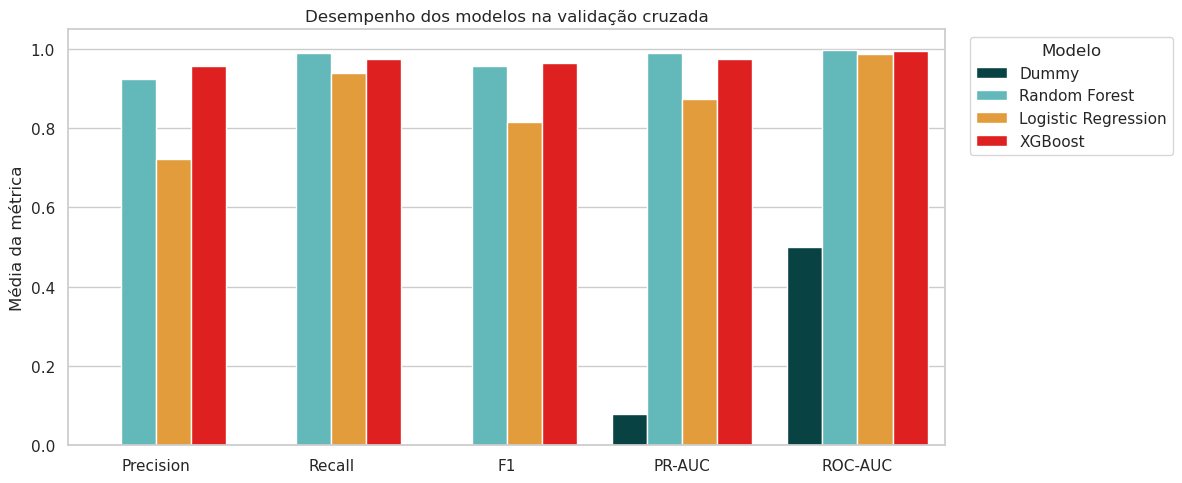

In [6]:

metricas_plot = ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]
df_metricas_plot = (
    df_resultados_cv[metricas_plot].reset_index()
    .melt(id_vars="Modelo", var_name="Métrica", value_name="Valor"))


fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=df_metricas_plot, x="Métrica", y="Valor", hue="Modelo",palette=models_cor,ax=ax)
ax.set(title="Desempenho dos modelos na validação cruzada",xlabel="", ylabel="Média da métrica", ylim=(0, 1.05)
)
ax.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Estabilidade dos modelos na validação cruzada

In [7]:
modelos_finalistas_cv = ["XGBoost", "Random Forest"]

metricas_cv = {
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "PR-AUC": "average_precision",
    "ROC-AUC": "roc_auc"
}

resultados_detalhados = []

for nome in modelos_finalistas_cv:

    scores = cross_validate(
        pipelines[nome],
        X_treino,
        y_treino,
        cv=cv,
        scoring=metricas_cv,
        n_jobs=1,
        error_score="raise"
    )

    for fold in range(cv.get_n_splits()):

        resultados_detalhados.append({
            "Modelo": nome,
            "Fold": fold + 1,
            **{
                metrica: scores[f"test_{metrica}"][fold]
                for metrica in metricas_cv
            }
        })

df_cv_detalhado = pd.DataFrame(resultados_detalhados)

display(
    df_cv_detalhado
    .set_index(["Modelo", "Fold"])
    .round(4)
)

resumo_cv = (
    df_cv_detalhado
    .groupby("Modelo")[list(metricas_cv)]
    .agg(["mean", "std"])
)

display(resumo_cv.round(4))

Precision  Recall    F1  PR-AUC  ROC-AUC
Modelo        Fold                                          
XGBoost       1         0.979   0.979 0.979   0.961    0.995
              2         0.939   0.979 0.958   0.998    1.000
              3         0.959   1.000 0.979   1.000    1.000
              4         0.957   0.978 0.968   0.944    0.985
              5         0.956   0.935 0.945   0.975    0.999
Random Forest 1         0.939   0.979 0.958   0.986    0.999
              2         0.979   1.000 0.990   1.000    1.000
              3         0.870   1.000 0.931   1.000    1.000
              4         0.938   0.978 0.957   0.981    0.998
              5         0.902   1.000 0.949   0.983    0.999

Precision       Recall          F1       PR-AUC       ROC-AUC  \
                   mean   std   mean   std  mean   std   mean   std    mean   
Modelo                                                                        
Random Forest     0.926 0.041  0.991 0.012 0.957 0.021  0.990 0.009   0.999   
XGBoost           0.958 0.014  0.974 0.024 0.966 0.015  0.976 0.024   0.996   

                     
                std  
Modelo               
Random Forest 0.001  
XGBoost       0.006

### **Comentário**
A análise de estabilidade na validação cruzada evidencia desempenho elevado para XGBoost e Random Forest, embora existam diferenças na consistência das métricas.

O XGBoost apresentou o maior F1 médio (0,966), com desvio-padrão de 0,015, indicando resultados relativamente consistentes entre os cinco folds. O Random Forest obteve maior Recall médio (0,991) e maior PR-AUC (0,990), além de apresentar baixa variabilidade nessas métricas.

Por outro lado, o Random Forest apresentou maior variação em Precision (desvio-padrão de 0,041), enquanto o XGBoost manteve resultados mais uniformes nessa métrica. Para o F1, a diferença de variabilidade entre os modelos foi pequena.

Em conjunto, os resultados mostram que os dois algoritmos apresentam desempenho consistente, mas com características distintas: o XGBoost se destaca pelo F1 médio, enquanto o Random Forest apresenta maior capacidade de recuperação da classe minoritária e melhor PR-AUC.

Essa comparação ainda não determina o modelo definitivo. A decisão deverá considerar as análises complementares e, posteriormente, a avaliação no conjunto de validação reservado.

## 7. Importância das variáveis

In [8]:
# Importância por permutação — quatro modelos
df_importancia_dm = importancia_permutacao_cv(
    pipelines["Dummy"], X_treino, y_treino, cv=cv
)

df_importancia_lr = importancia_permutacao_cv(
    pipelines["Logistic Regression"], X_treino, y_treino, cv=cv
)

df_importancia_xgb = importancia_permutacao_cv(
    pipelines["XGBoost"], X_treino, y_treino, cv=cv
)

df_importancia_rf = importancia_permutacao_cv(
    pipelines["Random Forest"], X_treino, y_treino, cv=cv)


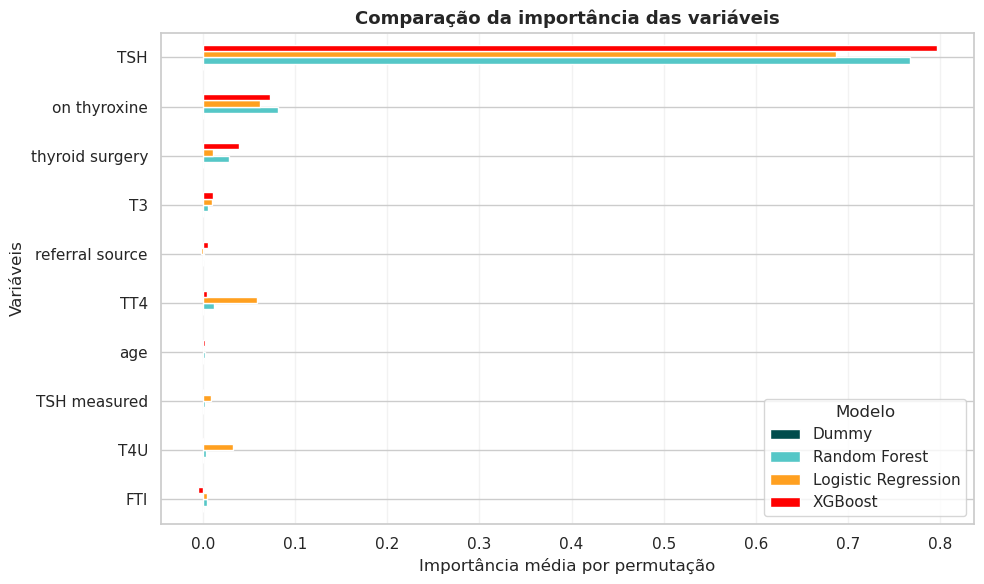

In [10]:
importancia_comparada = pd.concat(
    [
        df_importancia_dm["Importancia_media"].rename("Dummy"),
        df_importancia_rf["Importancia_media"].rename("Random Forest"),
        df_importancia_lr["Importancia_media"].rename("Logistic Regression"),
        df_importancia_xgb["Importancia_media"].rename("XGBoost"),
    ],
    axis=1
)

importancia_comparada["media_modelos"] = (
    importancia_comparada[models_name]
    .mean(axis=1)
)

top_variaveis = (
    importancia_comparada
    .sort_values("media_modelos", ascending=False)
    .head(10)
    .drop(columns="media_modelos")
    .sort_values("XGBoost")
)

ax = top_variaveis.plot(
    kind="barh",
    figsize=(10, 6),
    color=models_cor)

ax.set_title(
    "Comparação da importância das variáveis",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Importância média por permutação")
ax.set_ylabel("Variáveis")
ax.grid(axis="x", alpha=0.25)
ax.legend(title="Modelo")

plt.tight_layout()
plt.show()

### **Comentários**

A análise de importância por permutação dos quatro modelos evidencia uma concentração expressiva da contribuição preditiva em poucas variáveis.

O TSH apresenta a maior importância nos três modelos preditivos, com valores de 0,796 no XGBoost, 0,767 no Random Forest e 0,687 na Regressão Logística. Essa convergência indica que a variável exerce papel predominante no desempenho dos algoritmos.

A variável `on thyroxine` ocupa a segunda posição nos três modelos. Já `thyroid surgery` apresenta maior relevância nos modelos baseados em árvores, enquanto `TT4` e `T4U` demonstram maior importância relativa na Regressão Logística.

As demais variáveis apresentam contribuições individuais reduzidas ou próximas de zero. O modelo Dummy, por não utilizar efetivamente os preditores para realizar classificações, não apresenta importância discriminativa por permutação.

Em conjunto, os resultados mostram que, apesar das diferenças entre os algoritmos, existe forte convergência quanto à predominância do TSH. Esse achado reforça a necessidade de investigar a dependência dos modelos em relação a essa variável, especialmente por meio da análise de sensibilidade sem TSH.

Valores positivos indicam que a permutação reduz a PR-AUC, sugerindo contribuição para as predições. Valores próximos de zero indicam contribuição limitada nessa configuração; valores negativos podem ocorrer por variação amostral. A importância não representa causalidade.

## 8. Análise de sensibilidade: modelos sem TSH

A análise sem `TSH` investiga quanto o desempenho depende dessa variável. Os demais preditores e parâmetros são mantidos, e a avaliação continua restrita à validação cruzada no treinamento.

In [11]:
if "TSH" not in X_treino.columns:
    raise KeyError("A variável TSH não foi encontrada.")

X_treino_sem_tsh = X_treino.drop(columns="TSH")
numerical_features_sem_tsh = [c for c in numerical_features if c != "TSH"]

preprocessor_sem_tsh = ColumnTransformer([
    ("num", numeric_transformer, numerical_features_sem_tsh),
    ("bin", binary_transformer, binary_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")


modelos_sem_tsh=models

pipelines_sem_tsh = {
    nome: Pipeline([
        ("preprocessor", preprocessor_sem_tsh), ("classifier", modelo)
    ])
    for nome, modelo in modelos_sem_tsh.items()
}

resultados_sem_tsh = []
for nome, pipeline in pipelines_sem_tsh.items():
    scores = cross_validate(
        pipeline, X_treino_sem_tsh, y_treino,
        cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
    )
    resultados_sem_tsh.append({
        "Modelo": nome,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

df_resultados_sem_tsh = pd.DataFrame(resultados_sem_tsh).set_index("Modelo")
display(df_resultados_sem_tsh.round(4))

,Precision,Recall,F1,PR-AUC,ROC-AUC
Modelo,,,,,
Dummy,0.000,0.000,0.000,0.079,0.500
Random Forest,0.558,0.446,0.493,0.545,0.865
Logistic Regression,0.246,0.764,0.372,0.539,0.877
XGBoost,0.329,0.661,0.439,0.558,0.867


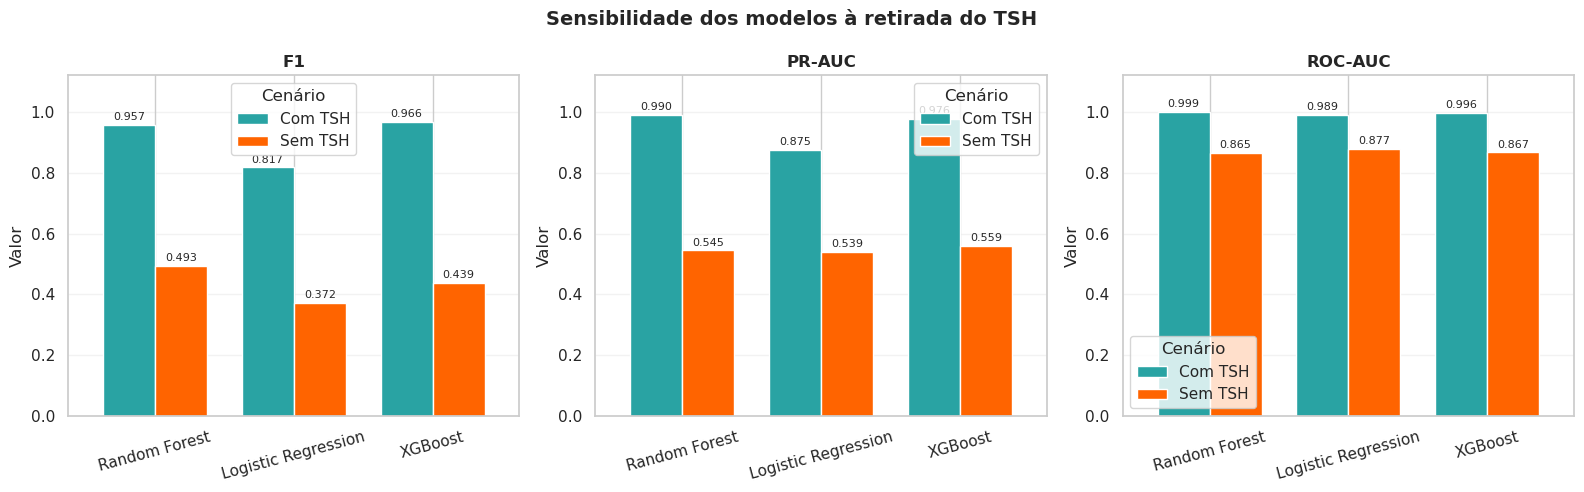

In [12]:
metricas = ["F1", "PR-AUC", "ROC-AUC"]

comparacao_tsh = pd.concat([
    df_resultados_cv.loc[models_name[1:4], metricas].assign(
        Modelo=models_name[1:4],
        Cenário="Com TSH"
    ),
    df_resultados_sem_tsh.loc[models_name[1:4], metricas].assign(
        Modelo=models_name[1:4],
        Cenário="Sem TSH"
    )
], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metrica in zip(axes, metricas):

    pivot = comparacao_tsh.pivot(
        index="Modelo",
        columns="Cenário",
        values=metrica
    ).reindex(
        index=models_name[1:4],
        columns=["Com TSH", "Sem TSH"]
    )

    pivot.plot(
        kind="bar",
        ax=ax,
        color=cor_N(COR,2,4),
        width=0.75
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.3f",
            padding=2,
            fontsize=8
        )

    ax.set_title(metrica, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Valor")
    ax.set_ylim(0, 1.12)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=15)
    ax.legend(title="Cenário")

fig.suptitle(
    "Sensibilidade dos modelos à retirada do TSH",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### **Comentários**

A análise de sensibilidade evidencia uma redução expressiva no desempenho dos três modelos após a retirada da variável TSH. O F1 do XGBoost caiu de 0,966 para 0,439, enquanto o Random Forest passou de 0,957 para 0,493 e a Regressão Logística de 0,817 para 0,372.

Entre os modelos avaliados sem TSH, o Random Forest apresentou o maior F1 (0,493), enquanto a Regressão Logística obteve o maior Recall (0,764). Entretanto, os resultados também revelam limitações na identificação da classe minoritária, especialmente para o Random Forest, cujo Recall foi reduzido para 0,446.

A PR-AUC também apresentou queda acentuada em todos os modelos, passando de valores entre 0,875 e 0,990 para aproximadamente 0,54 a 0,56. Apesar dessa redução, os resultados permanecem superiores à referência do modelo Dummy (0,079).

Em conjunto, os resultados reforçam a elevada dependência dos modelos em relação ao TSH. Embora outras variáveis ainda apresentem informação discriminativa, sua contribuição não foi suficiente para preservar o desempenho observado no cenário original. Essa constatação é coerente com a análise de importância por permutação, na qual o TSH apresentou contribuição predominante nos três modelos preditivos.

A retirada do TSH provocou redução expressiva no F1 e na PR-AUC dos três modelos, evidenciando a perda de desempenho na identificação da classe minoritária. Entretanto, a ROC-AUC apresentou redução menos acentuada, permanecendo entre 0,865 e 0,877.

Esse comportamento indica que, mesmo sem TSH, os modelos ainda preservam alguma capacidade de discriminação entre as classes, embora apresentem maior dificuldade para realizar classificações positivas com precisão e equilíbrio entre Precision e Recall.

Portanto, a análise evidencia que a contribuição do TSH é particularmente importante para o desempenho preditivo dos modelos, mas não representa a única fonte de informação discriminativa disponível no conjunto de dados.

### 8.1 Importância das variáveis no cenário sem TSH

In [13]:
resultados_importancia_sem_tsh = []
for nome, pipeline in pipelines_sem_tsh.items():
    df_imp = importancia_permutacao_cv(
        pipeline, X_treino_sem_tsh, y_treino, cv=cv
    ).reset_index()
    df_imp["Modelo"] = nome
    resultados_importancia_sem_tsh.append(df_imp)

df_importancia_sem_tsh = pd.concat(
    resultados_importancia_sem_tsh, ignore_index=True)


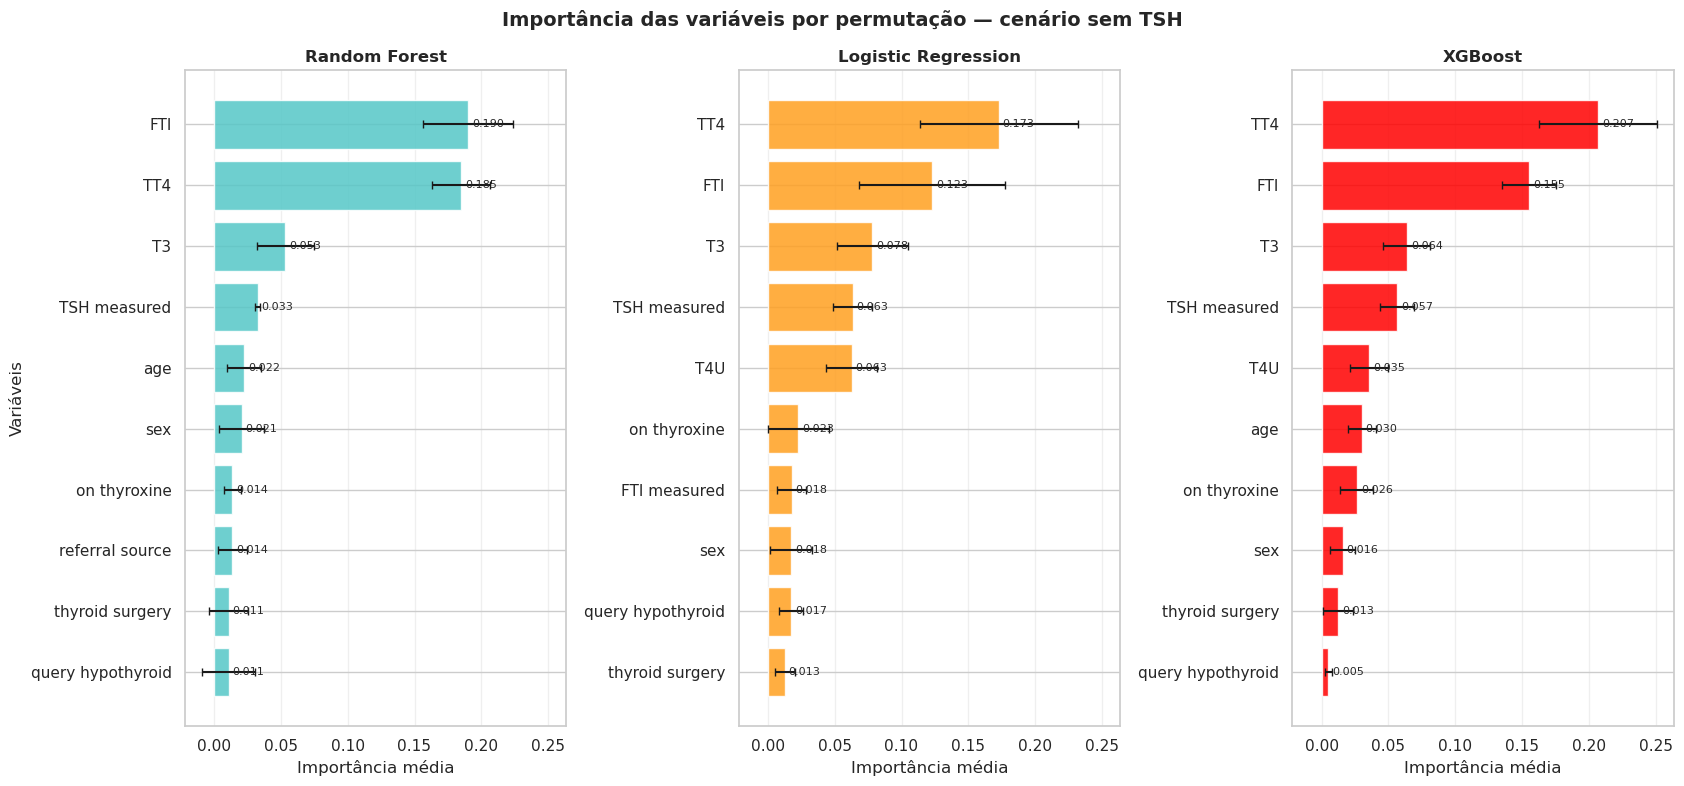

In [14]:

fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharex=True)

for ax, modelo in zip(axes, models_name[1:4]):

    dados = (
        df_importancia_sem_tsh[
            df_importancia_sem_tsh["Modelo"] == modelo
        ]
        .nlargest(10, "Importancia_media")
        .sort_values("Importancia_media", ascending=True))

    ax.barh(
        dados["Variavel"],
        dados["Importancia_media"],
        xerr=dados["Variabilidade_entre_folds"],
        capsize=3,
        color=dict_cor[modelo],
        alpha=0.85
    )

    ax.set_title(modelo, fontsize=12, fontweight="bold")
    ax.set_xlabel("Importância média")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

    for i, valor in enumerate(dados["Importancia_media"]):
        ax.text(valor + 0.003, i, f"{valor:.3f}",
                va="center", fontsize=8)

axes[0].set_ylabel("Variáveis")
fig.suptitle(
    "Importância das variáveis por permutação — cenário sem TSH",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### **comentários**
A análise de importância por permutação evidencia uma redistribuição da contribuição preditiva entre as variáveis após a retirada do TSH. Os indicadores hormonais TT4, FTI e T3 passam a concentrar as maiores importâncias nos três modelos avaliados.

No modelo de Regressão Logística e no XGBoost, TT4 apresenta a maior importância, enquanto no Random Forest essa posição é ocupada por FTI, com valor próximo ao de TT4. A variável T3 mantém a terceira posição nos três modelos. Também se observa a contribuição de TSH measured, indicando que a informação sobre a realização da medição de TSH permanece associada ao desempenho preditivo, mesmo sem a utilização de seu valor numérico.

Em conjunto, os resultados mostram que TT4, FTI e T3 preservam informação relevante para a classificação. Entretanto, essa contribuição não compensa integralmente a retirada do TSH, conforme demonstrado pela redução de desempenho observada na análise anterior.

## 9. Associação entre variáveis categóricas e a classe

,Variável,Teste,p-valor,V de Cramer
0,on thyroxine,Qui-quadrado,0.000,0.082
1,thyroid surgery,Fisher,0.371,0.024
2,query hypothyroid,Qui-quadrado,0.000,0.095
3,goitre,Fisher,0.164,0.029
4,TT4 measured,Qui-quadrado,0.095,0.034


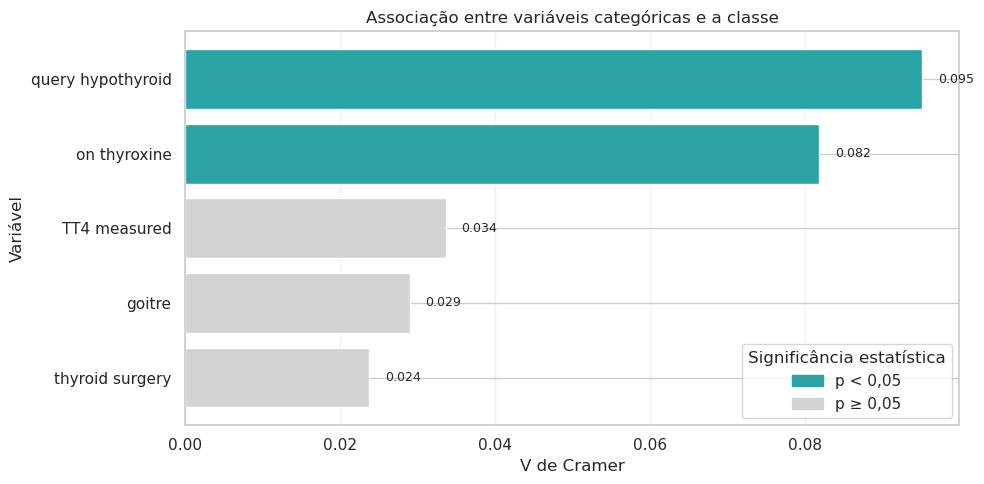

In [15]:
variaveis_interesse = [
    "on thyroxine", "thyroid surgery", "query hypothyroid",
    "goitre", "TT4 measured"
]

resultados_associacao = []
for variavel in variaveis_interesse:
    tabela = pd.crosstab(df_treino[variavel], df_treino[TARGET])
    qui2, p_chi2, _, esperadas = chi2_contingency(tabela)

    if tabela.shape == (2, 2) and (esperadas < 5).any():
        _, p_valor = fisher_exact(tabela)
        teste = "Fisher"
    else:
        p_valor = p_chi2
        teste = "Qui-quadrado"

    resultados_associacao.append({
        "Variável": variavel, "Teste": teste,
        "p-valor": p_valor,
        "V de Cramer": association(tabela, method="cramer")
    })

df_associacao = pd.DataFrame(resultados_associacao)
display(df_associacao.round(5))

df_plot = df_associacao.copy()

df_plot["Significativo"] = np.where(
    df_plot["p-valor"] < 0.05,
    "Significativo",
    "Não significativo"
)

df_plot = df_plot.sort_values("V de Cramer")

fig, ax = plt.subplots(figsize=(10, 5))

cores = df_plot["Significativo"].map({
    "Significativo": COR[4],
    "Não significativo": "lightgray"
})

barras = ax.barh(
    df_plot["Variável"],
    df_plot["V de Cramer"],
    color=cores
)

for barra, valor in zip(barras, df_plot["V de Cramer"]):
    ax.text(
        valor + 0.002,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

ax.set_title("Associação entre variáveis categóricas e a classe")
ax.set_xlabel("V de Cramer")
ax.set_ylabel("Variável")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color=COR[4], label="p < 0,05"),
        Patch(color="lightgray", label="p ≥ 0,05")
    ],
    title="Significância estatística"
)

plt.tight_layout()
plt.show()

### **Comentários**

Os testes de associação identificaram evidências estatísticas para as variáveis `on thyroxine` e `query hypothyroid`, ambas com p-valores inferiores a 0,001. Entretanto, os respectivos valores de V de Cramer (0,082 e 0,095) indicam associações de baixa intensidade.

As variáveis `thyroid surgery`, `goitre` e `TT4 measured` não apresentaram associações estatisticamente significativas com a classe ao nível de 5%.

Os resultados mostram que, embora algumas características clínicas estejam associadas à classificação, a intensidade dessas associações é reduzida. Portanto, a análise reforça a necessidade de considerar o conjunto de variáveis e suas relações no processo de classificação, em vez de avaliar os preditores isoladamente.

## 10. Síntese dos experimentos e modelos finalistas

A escolha dos modelos finalistas deve ser fundamentada nos resultados da validação cruzada e na estabilidade entre folds. O conjunto reservado não deve orientar a escolha, o ajuste de hiperparâmetros ou a seleção de variáveis.

,Precision,Recall,F1,PR-AUC,ROC-AUC
Modelo,,,,,
Dummy,0.000,0.000,0.000,0.079,0.500
Random Forest,0.926,0.991,0.957,0.990,0.999
Logistic Regression,0.723,0.940,0.817,0.875,0.989
XGBoost,0.958,0.974,0.966,0.976,0.996


Precision       Recall          F1       PR-AUC       ROC-AUC  \
                   mean   std   mean   std  mean   std   mean   std    mean   
Modelo                                                                        
Random Forest     0.926 0.041  0.991 0.012 0.957 0.021  0.990 0.009   0.999   
XGBoost           0.958 0.014  0.974 0.024 0.966 0.015  0.976 0.024   0.996   

                     
                std  
Modelo               
Random Forest 0.001  
XGBoost       0.006

Modelos definidos para avaliação final: ['XGBoost', 'Random Forest']


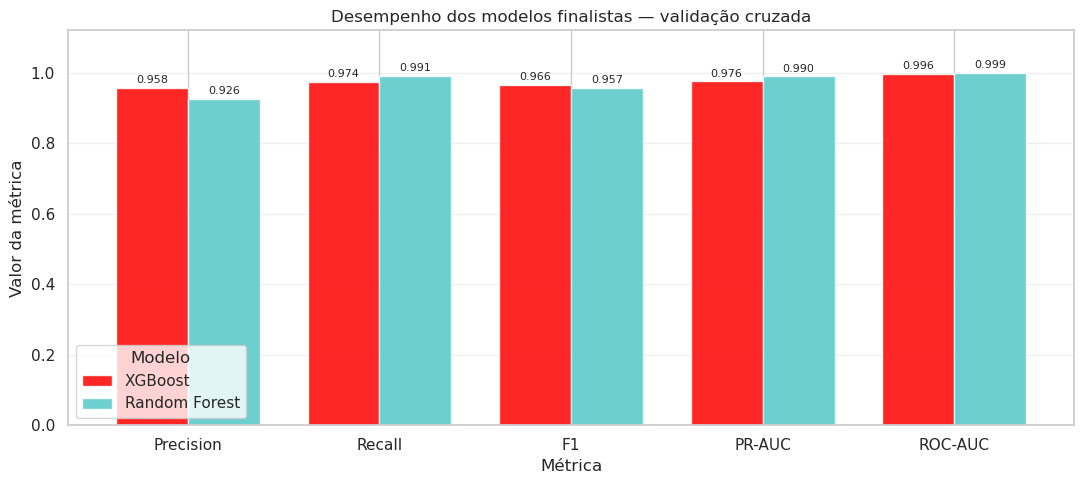

In [16]:
display(df_resultados_cv.round(4))
display(resumo_cv.round(4))

# Modelos definidos para comparação final
modelos_finalistas = {
    "XGBoost": pipelines["XGBoost"],
    "Random Forest": pipelines["Random Forest"]
}
print("Modelos definidos para avaliação final:", list(modelos_finalistas))

metricas = ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]

dados_plot = df_resultados_cv.loc[
    ["XGBoost", "Random Forest"], metricas
]

cores_plot = [dict_cor[m] for m in dados_plot.index]

ax = dados_plot.T.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75,
    color=cores_plot,
    alpha=0.85
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)

ax.set_title("Desempenho dos modelos finalistas — validação cruzada")
ax.set_ylabel("Valor da métrica")
ax.set_xlabel("Métrica")
ax.set_ylim(0, 1.12)
ax.legend(title="Modelo")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **Comentários**

A avaliação por validação cruzada identificou XGBoost e Random Forest como os modelos de melhor desempenho. O XGBoost apresentou o maior F1 (0,966), enquanto o Random Forest obteve os melhores resultados em Recall (0,991), PR-AUC (0,990) e ROC-AUC (0,999).

Apesar das diferenças, ambos demonstraram desempenho consistente entre os folds e foram selecionados para a avaliação final no conjunto reservado.

A seleção de dois modelos permite comparar abordagens com características distintas de classificação, mantendo a base de validação (`df_validacao`) preservada até esta etapa.

## 11. Avaliação final no conjunto de validação reservado

> **Etapa final — conjunto não utilizado no desenvolvimento**
>
> Somente nesta seção `df_validacao.csv` será carregado. Os modelos finalistas serão ajustados com todo o conjunto de treinamento e avaliados no conjunto reservado. Após esta etapa, os resultados devem ser reportados como avaliação final, sem novos ajustes orientados pelo holdout.

In [17]:
df_validacao = pd.read_csv(PATH_VALIDACAO)

if TARGET not in df_validacao.columns:
    raise KeyError(f"A variável-alvo {TARGET!r} não foi encontrada na validação.")
if df_validacao[TARGET].isna().any():
    raise ValueError("A variável-alvo contém valores ausentes na validação.")

X_validacao = df_validacao.drop(columns=TARGET).copy()
y_validacao = df_validacao[TARGET].astype(int).copy()

# Aplicar a mesma lista de exclusões identificada no treinamento
X_validacao = X_validacao.drop(columns=variaveis_constantes, errors="ignore")

colunas_ausentes = set(X_treino.columns) - set(X_validacao.columns)
colunas_extras = set(X_validacao.columns) - set(X_treino.columns)
if colunas_ausentes or colunas_extras:
    raise ValueError(
        f"Desalinhamento de colunas. Ausentes: {colunas_ausentes}; "
        f"Extras: {colunas_extras}"
    )

X_validacao = X_validacao[X_treino.columns].copy()
print(f"Treinamento: {X_treino.shape}")
print(f"Validação reservada: {X_validacao.shape}")

Treinamento: (2968, 26)
Validação reservada: (743, 26)


### **EXECUCAO**

In [18]:
resultados_finais = []
predicoes_finais = {}

for nome, modelo in modelos_finalistas.items():

    # Treinar com toda a base de treinamento
    modelo.fit(X_treino, y_treino)

    # Avaliar na base reservada
    y_pred = modelo.predict(X_validacao)
    y_prob = modelo.predict_proba(X_validacao)[:, 1]

    predicoes_finais[nome] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    resultados_finais.append({
        "Modelo": nome,
        "Precision": precision_score(y_validacao, y_pred),
        "Recall": recall_score(y_validacao, y_pred),
        "F1": f1_score(y_validacao, y_pred),
        "PR-AUC": average_precision_score(y_validacao, y_prob),
        "ROC-AUC": roc_auc_score(y_validacao, y_prob)
    })

df_resultados_finais = (
    pd.DataFrame(resultados_finais)
    .set_index("Modelo")
)

display(df_resultados_finais.round(4))

,Precision,Recall,F1,PR-AUC,ROC-AUC
Modelo,,,,,
XGBoost,1.000,0.983,0.991,1.000,1.000
Random Forest,0.983,1.000,0.992,1.000,1.000



XGBoost


,Previsto: P,Previsto: N
Real: P,685,0
Real: N,1,57



Random Forest


,Previsto: P,Previsto: N
Real: P,684,1
Real: N,0,58


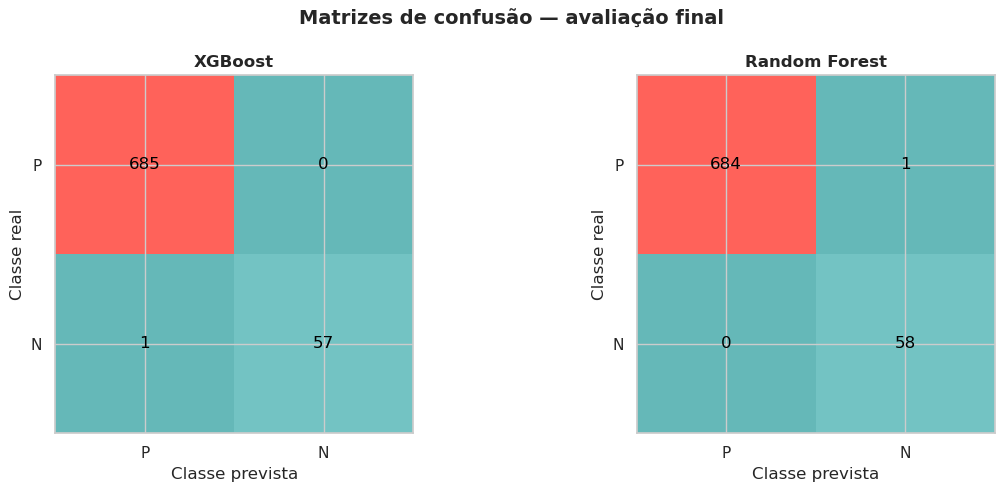

In [19]:
from matplotlib.colors import LinearSegmentedColormap


alpha = 0.65  # entre 0.0 (transparente) e 1.0 (opaco)

cmap_cor = LinearSegmentedColormap.from_list("custom_cor", COR2[5:40])
cmap_cor._init()
cmap_cor._lut[:, -1] = alpha


for nome, resultado in predicoes_finais.items():

    print(f"\n{nome}")
    cm = confusion_matrix(
        y_validacao,
        resultado["y_pred"]
    )

    display(pd.DataFrame(
        cm,
        index=["Real: P", "Real: N"],
        columns=["Previsto: P", "Previsto: N"]
    ))



fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nome, resultado) in zip(axes, predicoes_finais.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_validacao,
        resultado["y_pred"],
        display_labels=["P", "N"],
        cmap=cmap_cor,
        values_format="d",
        colorbar=False,
        text_kw={"color": "black"},
        ax=ax
    )

    ax.set_title(nome, fontsize=12, fontweight="bold")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

fig.suptitle(
    "Matrizes de confusão — avaliação final",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### **Comentário**

As matrizes de confusão demonstram que ambos os modelos apresentaram apenas um erro de classificação na base reservada, composta por 743 registros.

O XGBoost classificou corretamente 685 registros da classe P e 57 da classe N, apresentando um falso negativo. O Random Forest classificou corretamente 684 registros da classe P e 58 da classe N, apresentando um falso positivo. Embora ambos tenham registrado a mesma quantidade de erros, suas características são distintas: o XGBoost não apresentou falsos positivos, enquanto o Random Forest identificou todos os registros positivos. Essa diferença reflete o equilíbrio entre Precision e Recall observado na avaliação final.

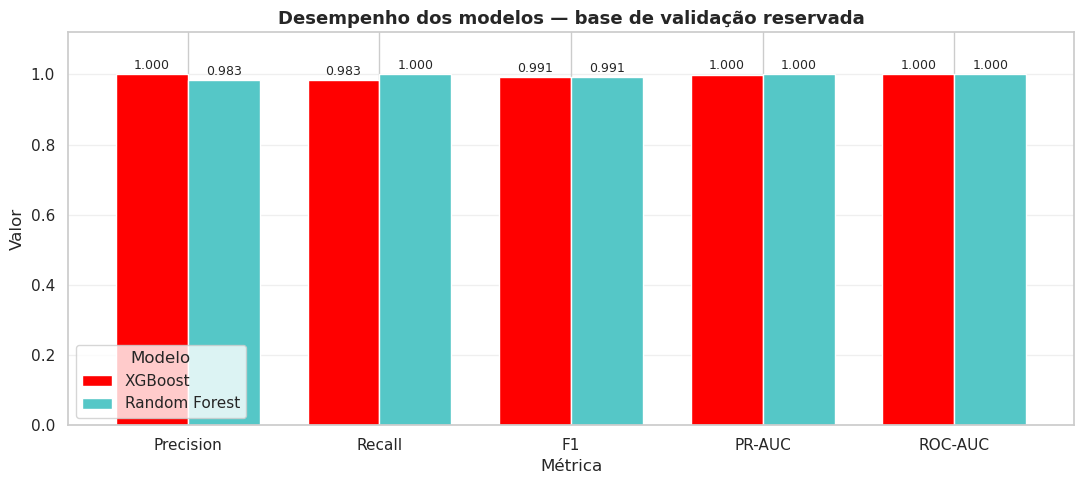

In [20]:
metricas = ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]

cores_plot = [dict_cor[m] for m in dados_plot.index]

ax = df_resultados_finais[metricas].T.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75,
   color=cores_plot)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=9)

ax.set_title(
    "Desempenho dos modelos — base de validação reservada",
    fontsize=13,
    fontweight="bold"
)
ax.set_ylabel("Valor")
ax.set_xlabel("Métrica")
ax.set_ylim(0, 1.12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(title="Modelo")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **Comentário**
A avaliação final confirmou o elevado desempenho dos dois modelos na base reservada. O XGBoost apresentou Precision de 1,000 e Recall de 0,983, enquanto o Random Forest alcançou Recall de 1,000 e Precision de 0,983.

Os valores de F1 foram praticamente equivalentes (0,991 para XGBoost e 0,992 para Random Forest). Ambos também obtiveram PR-AUC e ROC-AUC iguais a 1,000. Os resultados demonstram elevada capacidade de classificação no conjunto avaliado. Entretanto, o desempenho excepcional deve ser interpretado considerando as características e a origem dos dados, não sendo suficiente, isoladamente, para estabelecer capacidade de generalização clínica em outras populações.

A comparação visual reforça a proximidade entre os resultados dos modelos. Ambos apresentaram desempenho elevado, com apenas um erro de classificação cada. Entretanto, o XGBoost não apresentou falsos positivos, enquanto o Random Forest identificou todos os registros da classe positiva. As diferenças observadas refletem características distintas de classificação, sem estabelecer uma superioridade absoluta entre os modelos.

## 12. Considerações finais

A comparação por validação cruzada indicou XGBoost e Random Forest como os modelos de melhor desempenho. O XGBoost apresentou o maior F1 médio (0,966), enquanto o Random Forest obteve maior Recall (0,991), PR-AUC (0,990) e ROC-AUC (0,999). Os dois modelos foram mantidos como finalistas por apresentarem características complementares.

A análise de importância por permutação mostrou predominância do TSH nos três modelos preditivos. Na análise de sensibilidade sem essa variável, houve redução expressiva do F1: de 0,966 para 0,439 no XGBoost, de 0,957 para 0,493 no Random Forest e de 0,817 para 0,372 na Regressão Logística. Sem TSH, TT4, FTI e T3 concentraram as maiores importâncias.

Na análise de associação categórica, `on thyroxine` e `query hypothyroid` apresentaram evidência estatística de associação com a classe (p < 0,001), mas com baixa intensidade segundo o V de Cramer (0,082 e 0,095). As demais variáveis avaliadas não apresentaram associação estatisticamente significativa ao nível de 5%.

Na avaliação final dos 743 registros reservados, XGBoost e Random Forest apresentaram resultados muito próximos. O XGBoost obteve Precision de 1,000, Recall de 0,983 e F1 de 0,991. O Random Forest obteve Precision de 0,983, Recall de 1,000 e F1 de 0,992. Ambos alcançaram PR-AUC e ROC-AUC de 1,000 e apresentaram apenas um erro de classificação cada, em classes diferentes.

Assim, não há evidência suficiente nesta avaliação para declarar superioridade absoluta de um dos finalistas. Considerando `N` como a classe positiva, o XGBoost não apresentou falsos positivos, enquanto o Random Forest identificou todos os registros positivos da base reservada.

### Limitações e cuidados de interpretação

1. **Definição da variável-alvo:** a origem e o procedimento de construção de `binaryClass` não foram estabelecidos nesta análise. A predominância do TSH entre os preditores e a queda de desempenho sem essa variável justificam cautela. Caso o TSH tenha participado da definição dos rótulos, pode haver circularidade ou vazamento de informação; os resultados disponíveis, isoladamente, não permitem confirmar essa hipótese.
2. **Generalização:** o conjunto reservado contém 743 registros, mas foi separado da mesma base de dados. Trata-se, portanto, de uma avaliação holdout interna, não de validação externa em outra população, instituição ou período.
3. **Desbalanceamento:** a classe positiva `N` é minoritária, com 233 registros no treinamento e 58 no conjunto reservado. Assim, as métricas de Precision, Recall, F1 e PR-AUC devem ser consideradas em conjunto, e os resultados da classe minoritária devem ser interpretados considerando seu tamanho amostral.
4. **Interpretação clínica:** os modelos foram avaliados quanto à reprodução dos rótulos presentes na base Hypothyroid. O desempenho obtido não comprova capacidade de diagnóstico clínico, não substitui avaliação profissional e não demonstra validade em contextos reais de atendimento.
5. **Importância das variáveis e avaliação final:** a importância por permutação expressa contribuição preditiva no contexto dos modelos ajustados, não causalidade ou efeito clínico. Além disso, os resultados finais correspondem a uma única divisão holdout; a generalização para outros contextos exigiria avaliação em dados independentes.


<div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">

**Síntese final**

Os experimentos identificaram XGBoost e Random Forest como modelos de alto desempenho na reprodução da classificação disponível na base Hypothyroid. Na avaliação reservada, os resultados foram praticamente equivalentes, com diferenças pontuais entre precisão e sensibilidade. Entretanto, a forte dependência preditiva do TSH, a necessidade de esclarecer a origem da variável-alvo, o desbalanceamento da classe positiva e a ausência de validação externa limitam o alcance das conclusões. Portanto, os resultados demonstram desempenho de classificação nesta base, mas não estabelecem validade diagnóstica nem generalização clínica.

</div>


